In [ ]:
# Purpose:
#   Generate subtype-specific marker gene dot plots and UMAP coordinate exports
#   for all major immune lineages after final QC and sample-level filtering.
#
# Summary:
#   - Load finalized level-3–annotated Seurat objects for each immune lineage
#   - Exclude one outlier sample (Pool137_32) which had aberrant B-cell composition
#   - Recompute basic UMAP visualizations for quality confirmation
#   - Export UMAP coordinates for downstream figure assembly
#   - Identify differentially expressed marker genes per cell subtype
#   - Select top marker genes (FDR < 0.05, log2FC > 1) for each lineage
#   - Generate publication-ready dot plots with standardized color and size scales
#   - Save all dot plots as vector (SVG) files for Supplementary figures
#
# Cell types processed:
#   B, CD4 T, CD8 T, other T, Monocytes, Dendritic Cells, and NK cells
#
# Notes:
#   - Marker detection is performed within each lineage using level-3 identities
#   - Dot plot color encodes scaled average expression; dot size reflects %
#     of cells expressing each gene
#   - All figures are formatted for high-resolution, vector-based publication

# Header

In [1]:
setwd('/n/data1/dfci/surgonc/mittendorf/lab/chelsea/iw/github')
source('codes/functions.R')

Loading required package: SeuratObject

Loading required package: sp


Attaching package: ‘SeuratObject’


The following objects are masked from ‘package:base’:

    intersect, t



Attaching package: ‘dplyr’


The following object is masked from ‘package:gridExtra’:

    combine


The following objects are masked from ‘package:stats’:

    filter, lag


The following objects are masked from ‘package:base’:

    intersect, setdiff, setequal, union



Attaching package: ‘anndata’


The following object is masked from ‘package:SeuratObject’:

    Layers




In [2]:
library(svglite)

# Celltype markers

## B

In [3]:
celltype = 'B'

In [4]:
ft = qs::qread(glue('data_v1/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 51643 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [17]:
ft <- subset(
  ft,
  subset = dataset_name != "Pool137_32"
)

length(unique(ft@meta.data$dataset_name))

[1] 55

In [8]:
ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))

ft
length(unique(ft@meta.data$dataset_name))

An object of class Seurat 
28202 features across 49158 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

[1] 55

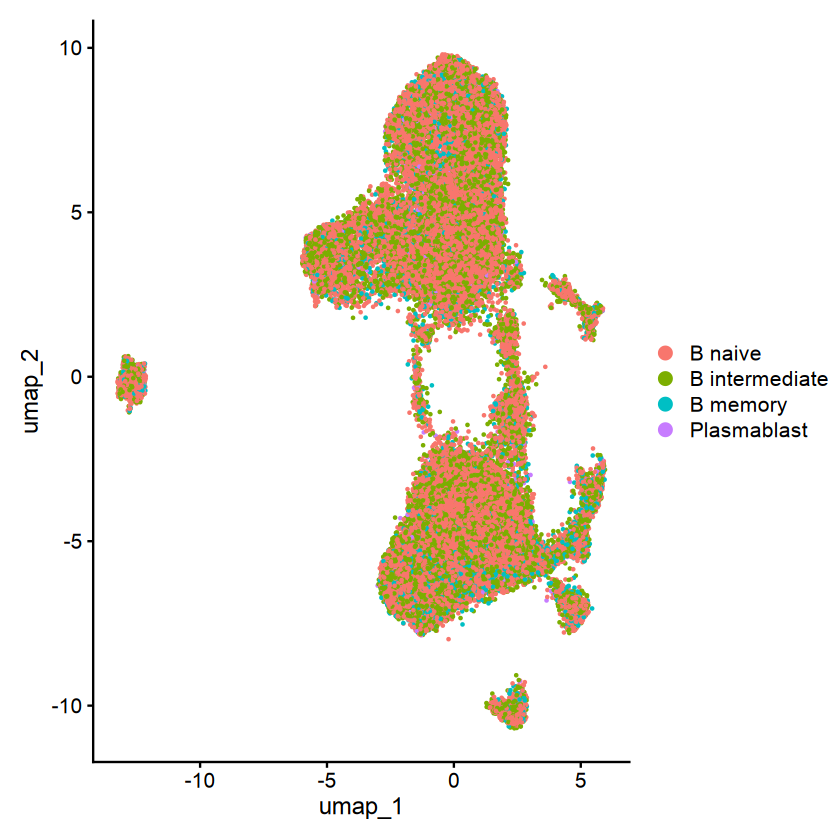

In [9]:
DimPlot(
  ft,
  reduction = "umap",
  group.by = NULL,   # or metadata column, e.g. "celltype"
  pt.size = 0.1
)

In [11]:
umap_df <- Embeddings(ft, reduction = "umap")
umap_df <- as.data.frame(umap_df)
umap_df$barcode <- rownames(umap_df)

write.csv(
  umap_df,
  file = glue("data/03_cleandata/ft_{celltype}_UmapCoords.csv"),
  row.names = FALSE
)

In [19]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster Naive B

Calculating cluster Mature B

Calculating cluster Memory B

Calculating cluster Plasmablast



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
TCL1A,0,4.526189,0.832,0.057,0,Naive B,TCL1A
CRIP1,0,-2.771695,0.278,0.763,0,Naive B,CRIP1
IL4R,0,2.842627,0.560,0.104,0,Naive B,IL4R
FCER2,0,2.204127,0.713,0.263,0,Naive B,FCER2
IGHD,0,2.038834,0.619,0.202,0,Naive B,IGHD
TNFRSF13B,0,-3.188286,0.054,0.467,0,Naive B,TNFRSF13B


In [20]:
write.csv(markers, 
          glue('data/04_markergenes/{celltype}.csv'))

In [21]:
# markers = read.csv(glue('data/04_markergenes/{celltype}.csv'),
#                    row.names=1
#                   )

cell_ordered = c(
    "Naive B",
    "Mature B",
    "Memory B",
    "Plasmablast"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)

markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 5) %>% # top 5 genes
    ungroup() -> top

top

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,4.526189,0.832,0.057,0,Naive B,TCL1A
0,2.842627,0.560,0.104,0,Naive B,IL4R
0,2.204127,0.713,0.263,0,Naive B,FCER2
0,2.038834,0.619,0.202,0,Naive B,IGHD
0,2.242738,0.592,0.223,0,Naive B,PLPP5
0,1.576355,0.621,0.263,0,Mature B,GPR183
0,1.877130,0.472,0.149,0,Mature B,TNFRSF13B
0,1.004270,0.716,0.439,0,Mature B,COTL1
0,1.300270,0.550,0.275,0,Mature B,VOPP1


Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


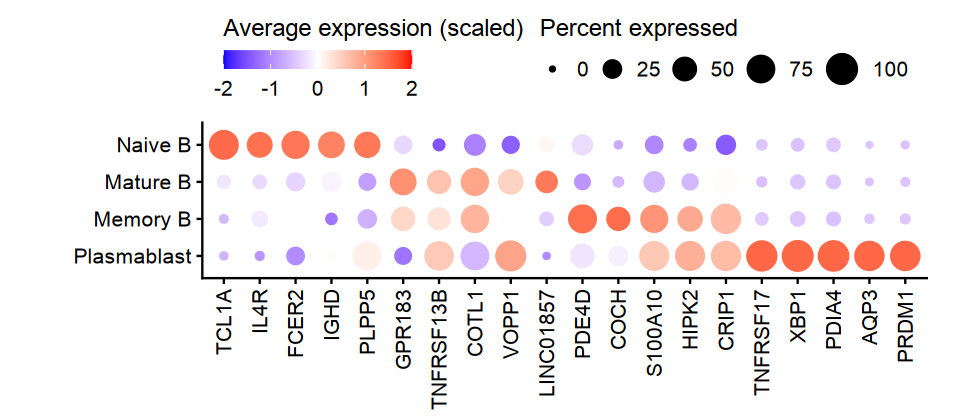

In [45]:
options(repr.plot.width = 8, repr.plot.height = 3.5)

dot_limits <- c(-2, 2)

p <- DotPlot(
  object   = ft,
  features = unique(unlist(top$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0,
    limits = dot_limits
  ) +
  scale_size(range = c(1, 8), limits = c(0, 100)) +
  scale_y_discrete(limits = rev) +
  theme(
    legend.position = "top",
    legend.direction = "horizontal",
    legend.box = "horizontal",
    legend.justification = "center",
    axis.text.x  = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin  = margin(t = 10, r = 20, b = 10, l = 50)
  ) +
  guides(
    colour = guide_colourbar(
      title = "Average expression (scaled)",
      direction = "horizontal",
      title.position = "top",
      barwidth  = unit(4, "cm"),
      barheight = unit(0.4, "cm")
    ),
    size = guide_legend(
      title = "Percent expressed",
      direction = "horizontal",
      nrow = 1,
      byrow = TRUE,
      title.position = "top"
    )
  )

print(p)

In [47]:
ggsave(
  filename = glue("plots/S1/dotplot_{celltype}.svg"),
  plot = p,
  width = 8, height = 3.5, units = "in", # match your original plot
  device = svglite,                     # ensure vector output
  dpi = 600
)

## CD4 T

In [12]:
celltype = 'CD4 T'

In [49]:
ft = qs::qread(glue('data_v1/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 168410 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [50]:
ft <- subset(
  ft,
  subset = dataset_name != "Pool137_32"
)

length(unique(ft@meta.data$dataset_name))

[1] 55

In [13]:
ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))

ft
length(unique(ft@meta.data$dataset_name))

An object of class Seurat 
28202 features across 167053 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

[1] 55

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



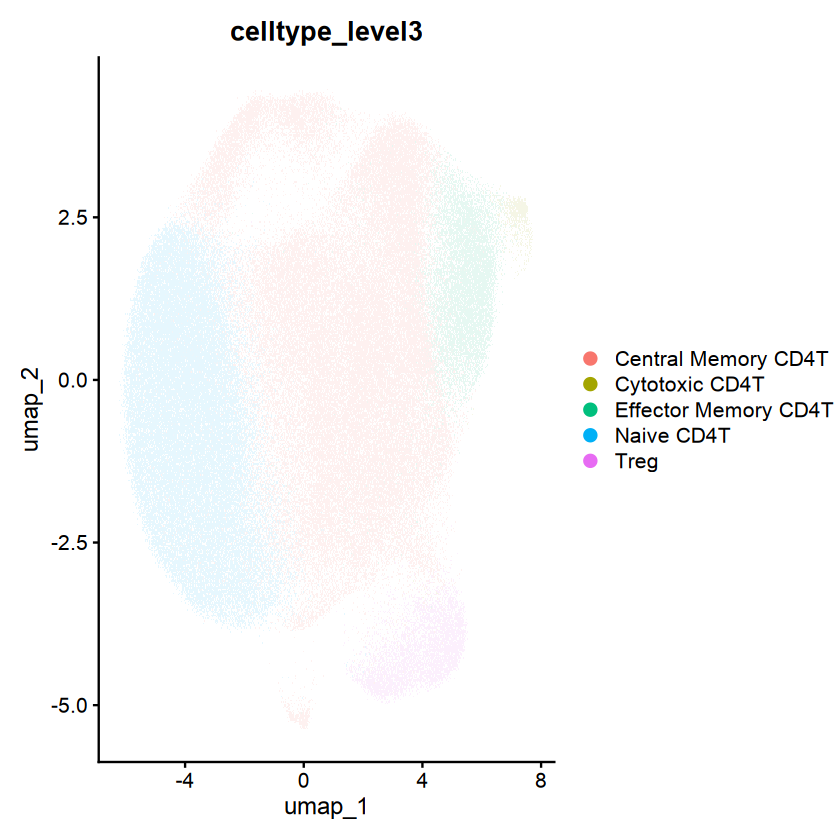

In [17]:
DimPlot(
  ft,
  reduction = "umap",
  group.by = "celltype_level3",
  pt.size = 0.1
)

In [15]:
umap_df <- Embeddings(ft, reduction = "umap")
umap_df <- as.data.frame(umap_df)
umap_df$barcode <- rownames(umap_df)

write.csv(
  umap_df,
  file = glue("data/03_cleandata/ft_{celltype}_UmapCoords.csv"),
  row.names = FALSE
)

In [52]:
# ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 167053 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [54]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster Naive CD4T

Calculating cluster Central Memory CD4T

Calculating cluster Cytotoxic CD4T

Calculating cluster Effector Memory CD4T

Calculating cluster Treg



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
ITGB1,0,-3.057687,0.113,0.594,0,Naive CD4T,ITGB1
AHNAK,0,-2.358092,0.249,0.722,0,Naive CD4T,AHNAK
S100A11,0,-2.212945,0.218,0.636,0,Naive CD4T,S100A11
S100A4,0,-2.398947,0.462,0.878,0,Naive CD4T,S100A4
FHIT,0,1.497428,0.682,0.288,0,Naive CD4T,FHIT
ANXA1,0,-1.533602,0.380,0.708,0,Naive CD4T,ANXA1


In [55]:
cell_ordered = c(
    "Naive CD4T",
    "Central Memory CD4T",
    "Effector Memory CD4T",
    "Cytotoxic CD4T", 
    "Treg"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)

markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 5) %>% # top 5 genes
    ungroup() -> top

top

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,1.497428,0.682,0.288,0,Naive CD4T,FHIT
0,1.204573,0.697,0.399,0,Naive CD4T,CCR7
0,1.115192,0.693,0.416,0,Naive CD4T,BACH2
0,1.160398,0.401,0.217,0,Naive CD4T,SATB1
0,1.273960,0.330,0.160,0,Naive CD4T,NUCB2
0,1.422489,0.596,0.239,0,Central Memory CD4T,ITGB1
0,1.184409,0.714,0.382,0,Central Memory CD4T,AHNAK
0,1.150113,0.633,0.333,0,Central Memory CD4T,S100A11
0,1.079141,0.732,0.443,0,Central Memory CD4T,ANXA1


Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


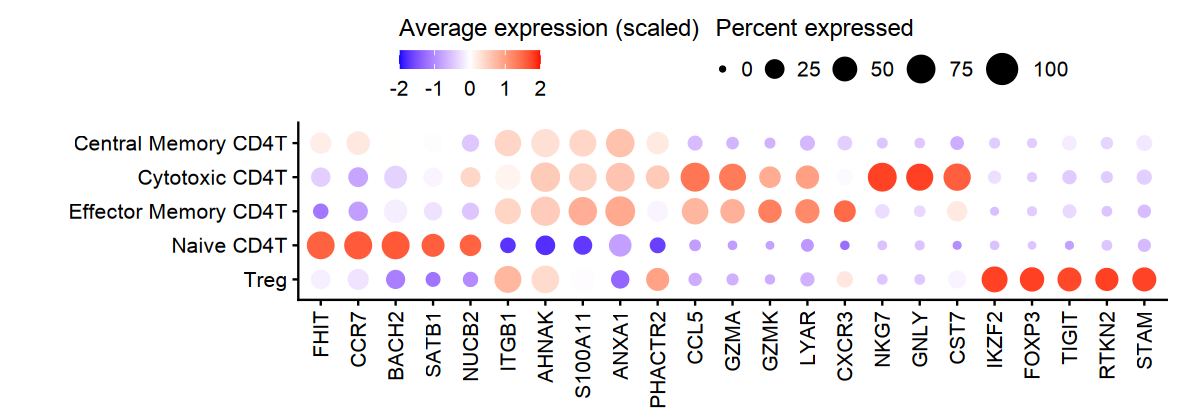

In [61]:
options(repr.plot.width = 10, repr.plot.height = 3.5)

dot_limits <- c(-2, 2)

p <- DotPlot(
  object   = ft,
  features = unique(unlist(top$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0,
    limits = dot_limits
  ) +
  scale_size(range = c(1, 8), limits = c(0, 100)) +
  scale_y_discrete(limits = rev) +
  theme(
    legend.position = "top",
    legend.direction = "horizontal",
    legend.box = "horizontal",
    legend.justification = "center",
    axis.text.x  = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin  = margin(t = 10, r = 20, b = 10, l = 50)
  ) +
  guides(
    colour = guide_colourbar(
      title = "Average expression (scaled)",
      direction = "horizontal",
      title.position = "top",
      barwidth  = unit(3, "cm"),
      barheight = unit(0.4, "cm")
    ),
    size = guide_legend(
      title = "Percent expressed",
      direction = "horizontal",
      nrow = 1,
      byrow = TRUE,
      barwidth  = unit(.3, "cm"),
      title.position = "top"
    )
  )

print(p)

In [62]:
ggsave(
  filename = glue("plots/S1/dotplot_{celltype}.svg"),
  plot = p,
  width = 10, height = 3.5, units = "in", # match your original plot
  device = svglite,                     # ensure vector output
  dpi = 600
)

## CD8 T

In [18]:
celltype = 'CD8 T'

In [64]:
ft = qs::qread(glue('data_v1/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 56566 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [65]:
ft <- subset(
  ft,
  subset = dataset_name != "Pool137_32"
)

length(unique(ft@meta.data$dataset_name))

[1] 55

In [66]:
qs::qsave(ft, glue('data/03_cleandata/ft_{celltype}.qs'))

In [19]:
ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))

ft
length(unique(ft@meta.data$dataset_name))

An object of class Seurat 
28202 features across 56297 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

[1] 55

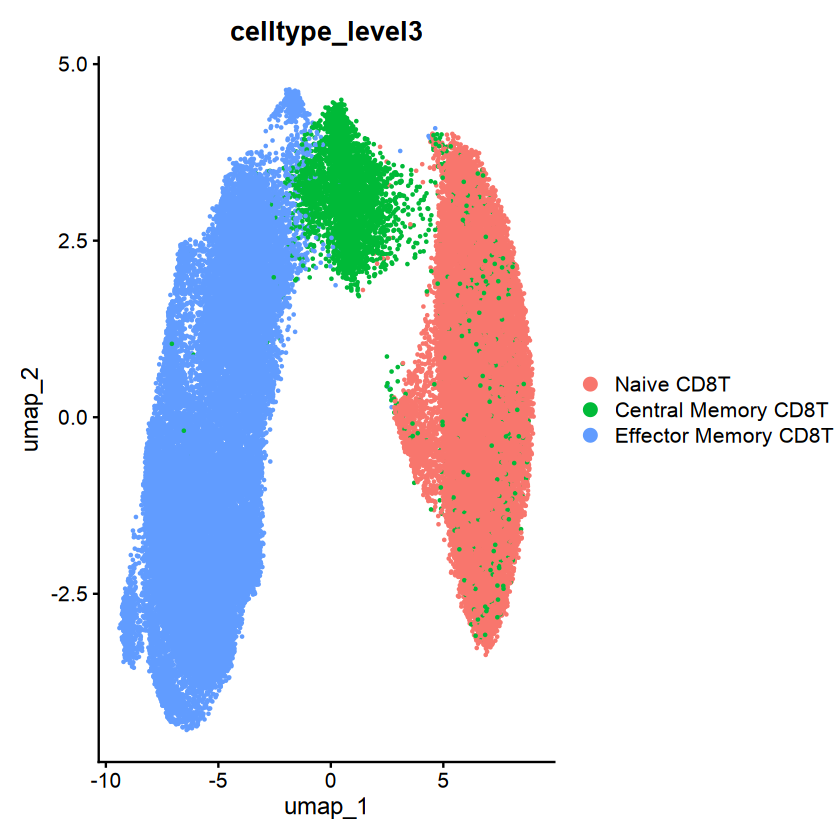

In [20]:
DimPlot(
  ft,
  reduction = "umap",
  group.by = "celltype_level3",
  pt.size = 0.1
)

In [21]:
umap_df <- Embeddings(ft, reduction = "umap")
umap_df <- as.data.frame(umap_df)
umap_df$barcode <- rownames(umap_df)

write.csv(
  umap_df,
  file = glue("data/03_cleandata/ft_{celltype}_UmapCoords.csv"),
  row.names = FALSE
)

In [67]:
# ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 56297 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [68]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster Naive CD8T

Calculating cluster Central Memory CD8T

Calculating cluster Effector Memory CD8T



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CCL5,0,-6.510821,0.068,0.984,0,Naive CD8T,CCL5
NKG7,0,-8.186471,0.048,0.936,0,Naive CD8T,NKG7
CST7,0,-8.796716,0.009,0.890,0,Naive CD8T,CST7
GZMA,0,-7.398524,0.017,0.822,0,Naive CD8T,GZMA
LEF1,0,3.254700,0.833,0.143,0,Naive CD8T,LEF1
GZMH,0,-10.962881,0.002,0.676,0,Naive CD8T,GZMH


In [69]:
cell_ordered = c(
    "Naive CD8T",
    "Central Memory CD8T",
    "Effector Memory CD8T"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)

markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 5) %>% # top 5 genes
    ungroup() -> top

top

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,3.254700,0.833,0.143,0,Naive CD8T,LEF1
0,3.780934,0.755,0.082,0,Naive CD8T,CCR7
0,3.006661,0.769,0.147,0,Naive CD8T,BACH2
0,2.523427,0.763,0.167,0,Naive CD8T,NELL2
0,2.134308,0.810,0.223,0,Naive CD8T,SELL
0,1.191616,0.959,0.589,0,Central Memory CD8T,LTB
0,1.300827,0.963,0.612,0,Central Memory CD8T,IL7R
0,1.021933,0.710,0.384,0,Central Memory CD8T,COTL1
0,1.241975,0.564,0.281,0,Central Memory CD8T,PLP2


Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


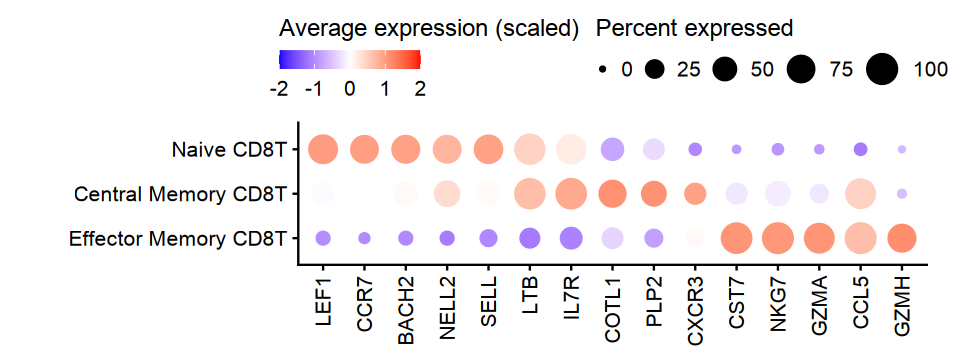

In [75]:
options(repr.plot.width = 8, repr.plot.height = 3)

dot_limits <- c(-2, 2)

p <- DotPlot(
  object   = ft,
  features = unique(unlist(top$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0,
    limits = dot_limits
  ) +
  scale_size(range = c(1, 8), limits = c(0, 100)) +
  scale_y_discrete(limits = rev) +
  theme(
    legend.position = "top",
    legend.direction = "horizontal",
    legend.box = "horizontal",
    legend.justification = "center",
    axis.text.x  = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin  = margin(t = 10, r = 20, b = 10, l = 50)
  ) +
  guides(
    colour = guide_colourbar(
      title = "Average expression (scaled)",
      direction = "horizontal",
      title.position = "top",
      barwidth  = unit(3, "cm"),
      barheight = unit(0.4, "cm")
    ),
    size = guide_legend(
      title = "Percent expressed",
      direction = "horizontal",
      nrow = 1,
      byrow = TRUE,
      barwidth  = unit(.3, "cm"),
      title.position = "top"
    )
  )

print(p)

In [77]:
ggsave(
  filename = glue("plots/S1/dotplot_{celltype}.svg"),
  plot = p,
  width = 8, height = 3, units = "in", # match your original plot
  device = svglite,                     # ensure vector output
  dpi = 600
)

## Other T

In [22]:
celltype = 'other T'

In [79]:
ft = qs::qread(glue('data_v1/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 8646 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [80]:
ft <- subset(
  ft,
  subset = dataset_name != "Pool137_32"
)

length(unique(ft@meta.data$dataset_name))

[1] 52

In [81]:
qs::qsave(ft, glue('data/03_cleandata/ft_{celltype}.qs'))

In [23]:
ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))

ft
length(unique(ft@meta.data$dataset_name))

An object of class Seurat 
28202 features across 8586 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

[1] 52

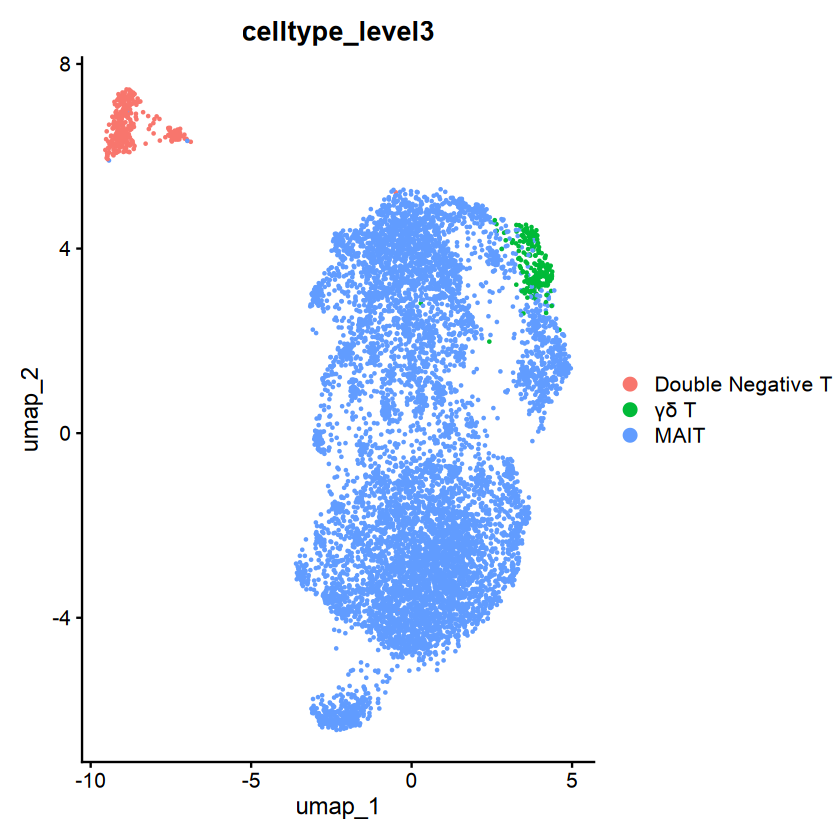

In [25]:
DimPlot(
  ft,
  reduction = "umap",
  group.by = "celltype_level3",
  pt.size = 0.1
)

In [26]:
umap_df <- Embeddings(ft, reduction = "umap")
umap_df <- as.data.frame(umap_df)
umap_df$barcode <- rownames(umap_df)

write.csv(
  umap_df,
  file = glue("data/03_cleandata/ft_{celltype}_UmapCoords.csv"),
  row.names = FALSE
)

In [82]:
# ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 8586 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [83]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster Double Negative T

Calculating cluster γδ T

Calculating cluster MAIT



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
LEF1,0,6.186438,0.627,0.014,0,Double Negative T,LEF1
AFF3,0,4.860087,0.586,0.034,0,Double Negative T,AFF3
SESTD1,0,9.584920,0.534,0.001,0,Double Negative T,SESTD1
TIGIT,0,5.587512,0.539,0.017,0,Double Negative T,TIGIT
TRPS1,0,4.560797,0.490,0.032,0,Double Negative T,TRPS1
FXYD2,0,5.614478,0.461,0.018,0,Double Negative T,FXYD2


In [85]:
cell_ordered = c(
    "Double Negative T",
    "γδ T",
    "MAIT"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)

markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 5) %>% # top 5 genes
    ungroup() -> top

top

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0.000000e+00,6.186438,0.627,0.014,0.000000e+00,Double Negative T,LEF1
0.000000e+00,4.860087,0.586,0.034,0.000000e+00,Double Negative T,AFF3
0.000000e+00,9.584920,0.534,0.001,0.000000e+00,Double Negative T,SESTD1
0.000000e+00,5.587512,0.539,0.017,0.000000e+00,Double Negative T,TIGIT
0.000000e+00,4.560797,0.490,0.032,0.000000e+00,Double Negative T,TRPS1
1.641836e-237,3.190758,0.825,0.107,4.577275e-233,γδ T,TRDV2
1.846094e-220,3.531128,0.659,0.071,5.146725e-216,γδ T,TRDC
2.731867e-151,2.589886,0.838,0.174,7.616171e-147,γδ T,TRGV9
1.968705e-106,3.367303,0.371,0.045,5.488553e-102,γδ T,GZMH


Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


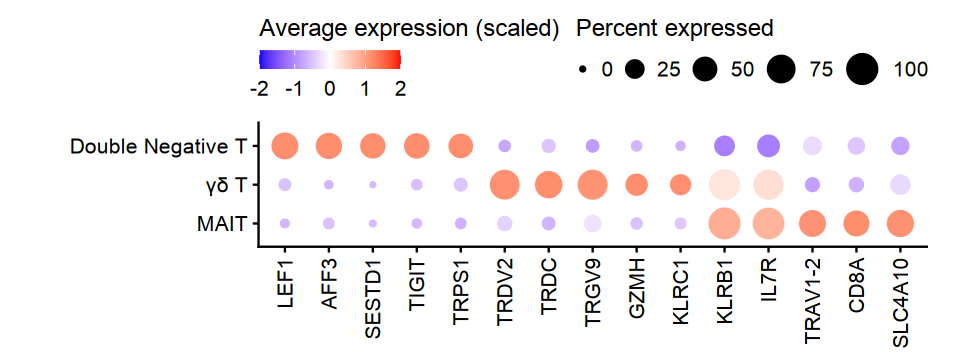

In [87]:
options(repr.plot.width = 8, repr.plot.height = 3)

dot_limits <- c(-2, 2)

p <- DotPlot(
  object   = ft,
  features = unique(unlist(top$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0,
    limits = dot_limits
  ) +
  scale_size(range = c(1, 8), limits = c(0, 100)) +
  scale_y_discrete(limits = rev) +
  theme(
    legend.position = "top",
    legend.direction = "horizontal",
    legend.box = "horizontal",
    legend.justification = "center",
    axis.text.x  = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin  = margin(t = 10, r = 20, b = 10, l = 50)
  ) +
  guides(
    colour = guide_colourbar(
      title = "Average expression (scaled)",
      direction = "horizontal",
      title.position = "top",
      barwidth  = unit(3, "cm"),
      barheight = unit(0.4, "cm")
    ),
    size = guide_legend(
      title = "Percent expressed",
      direction = "horizontal",
      nrow = 1,
      byrow = TRUE,
      barwidth  = unit(.3, "cm"),
      title.position = "top"
    )
  )

print(p)

In [88]:
ggsave(
  filename = glue("plots/S1/dotplot_{celltype}.svg"),
  plot = p,
  width = 8, height = 3, units = "in", # match your original plot
  device = svglite,                     # ensure vector output
  dpi = 600
)

## Mono

In [27]:
celltype = 'Mono'

In [90]:
ft = qs::qread(glue('data_v1/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 110990 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [91]:
ft <- subset(
  ft,
  subset = dataset_name != "Pool137_32"
)

length(unique(ft@meta.data$dataset_name))

[1] 55

In [92]:
qs::qsave(ft, glue('data/03_cleandata/ft_{celltype}.qs'))

In [28]:
ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))

ft
length(unique(ft@meta.data$dataset_name))

An object of class Seurat 
28202 features across 108864 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

[1] 55

Rasterizing points since number of points exceeds 100,000.
To disable this behavior set `raster=FALSE`



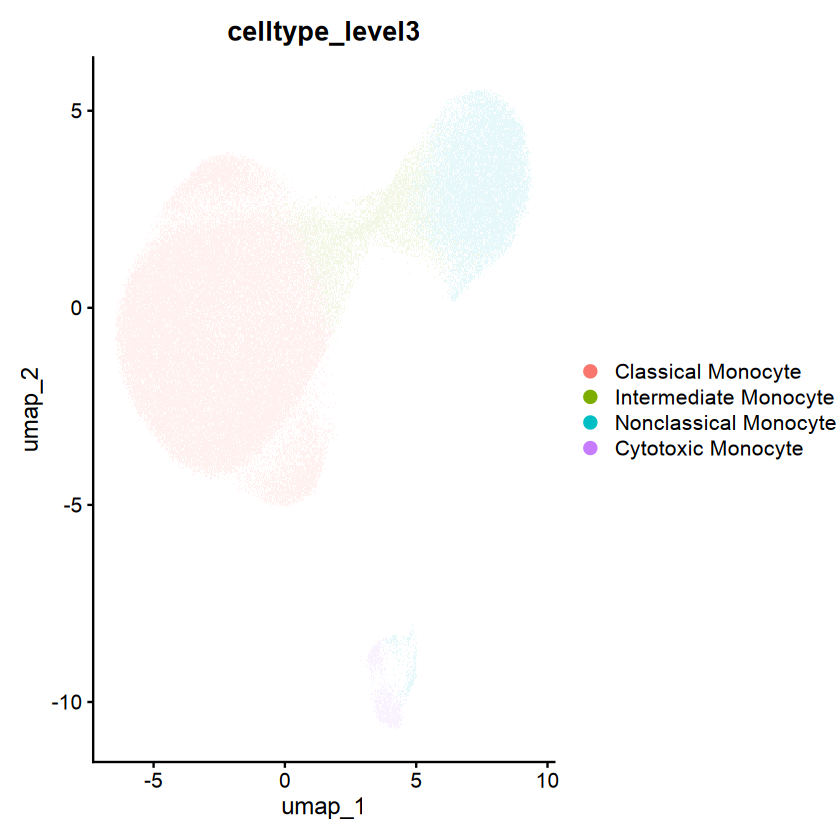

In [29]:
DimPlot(
  ft,
  reduction = "umap",
  group.by = "celltype_level3",
  pt.size = 0.1
)

In [30]:
umap_df <- Embeddings(ft, reduction = "umap")
umap_df <- as.data.frame(umap_df)
umap_df$barcode <- rownames(umap_df)

write.csv(
  umap_df,
  file = glue("data/03_cleandata/ft_{celltype}_UmapCoords.csv"),
  row.names = FALSE
)

In [93]:
# ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 108864 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [94]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster Classical Monocyte

Calculating cluster Intermediate Monocyte

Calculating cluster Nonclassical Monocyte

Calculating cluster Cytotoxic Monocyte



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
FCGR3A,0,-6.643537,0.042,0.833,0,Classical Monocyte,FCGR3A
CDKN1C,0,-6.613015,0.034,0.763,0,Classical Monocyte,CDKN1C
RHOC,0,-4.335634,0.091,0.772,0,Classical Monocyte,RHOC
S100A12,0,3.820605,0.795,0.117,0,Classical Monocyte,S100A12
TCF7L2,0,-3.019156,0.216,0.828,0,Classical Monocyte,TCF7L2
VCAN,0,3.418898,0.956,0.355,0,Classical Monocyte,VCAN


In [95]:
cell_ordered = c(
    "Classical Monocyte",
    "Intermediate Monocyte",
    "Nonclassical Monocyte",
    "Cytotoxic Monocyte"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)

markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 5) %>% # top 5 genes
    ungroup() -> top

top

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,3.820605,0.795,0.117,0,Classical Monocyte,S100A12
0,3.418898,0.956,0.355,0,Classical Monocyte,VCAN
0,2.681668,0.868,0.282,0,Classical Monocyte,CD14
0,2.583144,0.817,0.302,0,Classical Monocyte,CSF3R
0,2.649173,0.655,0.191,0,Classical Monocyte,SLC2A3
0,1.909016,0.671,0.259,0,Intermediate Monocyte,HLA-DQA1
0,1.100408,0.631,0.291,0,Intermediate Monocyte,ABI3
0,1.427765,0.599,0.288,0,Intermediate Monocyte,PLAC8
0,1.347468,0.668,0.370,0,Intermediate Monocyte,APOBEC3A


Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


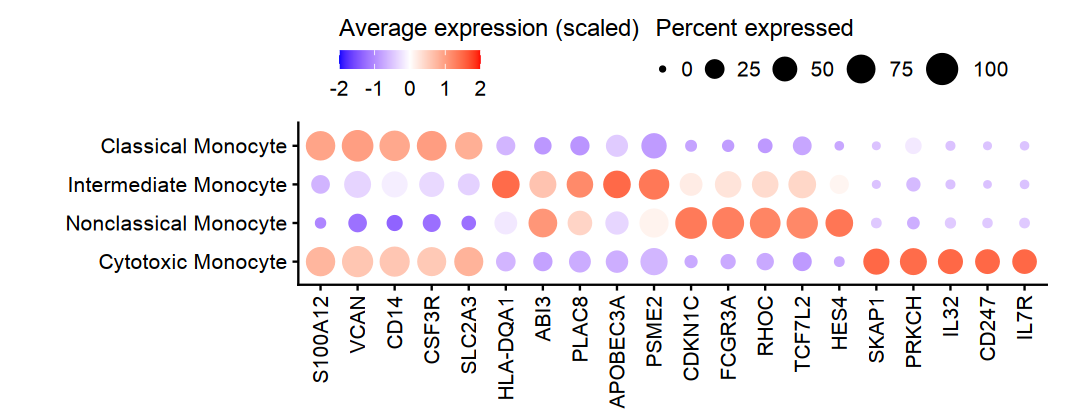

In [100]:
options(repr.plot.width = 9, repr.plot.height = 3.5)

dot_limits <- c(-2, 2)

p <- DotPlot(
  object   = ft,
  features = unique(unlist(top$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0,
    limits = dot_limits
  ) +
  scale_size(range = c(1, 8), limits = c(0, 100)) +
  scale_y_discrete(limits = rev) +
  theme(
    legend.position = "top",
    legend.direction = "horizontal",
    legend.box = "horizontal",
    legend.justification = "center",
    axis.text.x  = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin  = margin(t = 10, r = 20, b = 10, l = 50)
  ) +
  guides(
    colour = guide_colourbar(
      title = "Average expression (scaled)",
      direction = "horizontal",
      title.position = "top",
      barwidth  = unit(3, "cm"),
      barheight = unit(0.4, "cm")
    ),
    size = guide_legend(
      title = "Percent expressed",
      direction = "horizontal",
      nrow = 1,
      byrow = TRUE,
      barwidth  = unit(.3, "cm"),
      title.position = "top"
    )
  )

print(p)

In [101]:
ggsave(
  filename = glue("plots/S1/dotplot_{celltype}.svg"),
  plot = p,
  width = 9, height = 3.5, units = "in", # match your original plot
  device = svglite,                     # ensure vector output
  dpi = 600
)

## DC

In [31]:
celltype = 'DC'

In [103]:
ft = qs::qread(glue('data_v1/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 8012 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [104]:
ft <- subset(
  ft,
  subset = dataset_name != "Pool137_32"
)

length(unique(ft@meta.data$dataset_name))

[1] 55

In [32]:
ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))

ft
length(unique(ft@meta.data$dataset_name))

An object of class Seurat 
28202 features across 7936 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

[1] 55

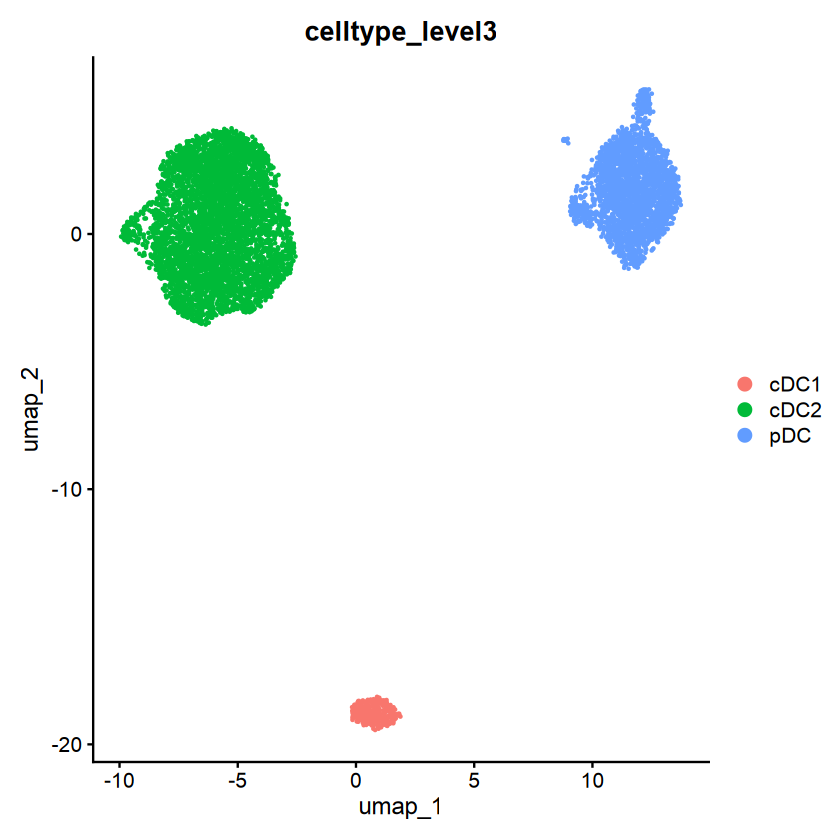

In [33]:
DimPlot(
  ft,
  reduction = "umap",
  group.by = "celltype_level3",
  pt.size = 0.1
)

In [34]:
umap_df <- Embeddings(ft, reduction = "umap")
umap_df <- as.data.frame(umap_df)
umap_df$barcode <- rownames(umap_df)

write.csv(
  umap_df,
  file = glue("data/03_cleandata/ft_{celltype}_UmapCoords.csv"),
  row.names = FALSE
)

In [106]:
# ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 7936 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [107]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster cDC1

Calculating cluster cDC2

Calculating cluster pDC



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
CLEC9A,0,8.684409,0.962,0.010,0,cDC1,CLEC9A
C1orf54,0,5.508204,0.971,0.083,0,cDC1,C1orf54
CLNK,0,6.276990,0.921,0.034,0,cDC1,CLNK
CADM1,0,9.496295,0.818,0.002,0,cDC1,CADM1
IDO1,0,6.546871,0.759,0.022,0,cDC1,IDO1
TMEM14A,0,3.416355,0.703,0.067,0,cDC1,TMEM14A


In [108]:
cell_ordered = c(
    "cDC1",
    "cDC2",
    "pDC"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)

markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 5) %>% # top 5 genes
    ungroup() -> top

top

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,8.684409,0.962,0.010,0,cDC1,CLEC9A
0,5.508204,0.971,0.083,0,cDC1,C1orf54
0,6.276990,0.921,0.034,0,cDC1,CLNK
0,9.496295,0.818,0.002,0,cDC1,CADM1
0,6.546871,0.759,0.022,0,cDC1,IDO1
0,5.686734,0.942,0.064,0,cDC2,CEBPD
0,5.669919,0.999,0.135,0,cDC2,IFI30
0,4.630328,0.962,0.104,0,cDC2,CFP
0,3.043576,1.000,0.144,0,cDC2,LYZ


Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


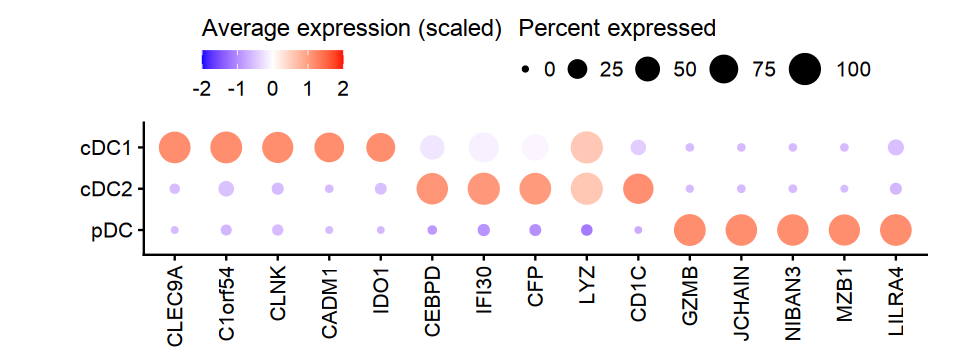

In [110]:
options(repr.plot.width = 8, repr.plot.height = 3)

dot_limits <- c(-2, 2)

p <- DotPlot(
  object   = ft,
  features = unique(unlist(top$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0,
    limits = dot_limits
  ) +
  scale_size(range = c(1, 8), limits = c(0, 100)) +
  scale_y_discrete(limits = rev) +
  theme(
    legend.position = "top",
    legend.direction = "horizontal",
    legend.box = "horizontal",
    legend.justification = "center",
    axis.text.x  = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin  = margin(t = 10, r = 20, b = 10, l = 50)
  ) +
  guides(
    colour = guide_colourbar(
      title = "Average expression (scaled)",
      direction = "horizontal",
      title.position = "top",
      barwidth  = unit(3, "cm"),
      barheight = unit(0.4, "cm")
    ),
    size = guide_legend(
      title = "Percent expressed",
      direction = "horizontal",
      nrow = 1,
      byrow = TRUE,
      barwidth  = unit(.3, "cm"),
      title.position = "top"
    )
  )

print(p)

In [112]:
ggsave(
  filename = glue("plots/S1/dotplot_{celltype}.svg"),
  plot = p,
  width = 8, height = 3, units = "in", # match your original plot
  device = svglite,                     # ensure vector output
  dpi = 600
)

## NK

In [35]:
celltype = 'NK'

In [120]:
ft = qs::qread(glue('data_v1/03_cleandata/ft_{celltype}.qs'))
ft

An object of class Seurat 
28202 features across 37050 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

In [121]:
ft <- subset(
  ft,
  subset = dataset_name != "Pool137_32"
)

length(unique(ft@meta.data$dataset_name))

[1] 55

In [36]:
ft = qs::qread(glue('data/03_cleandata/ft_{celltype}.qs'))

ft
length(unique(ft@meta.data$dataset_name))

An object of class Seurat 
28202 features across 36671 samples within 5 assays 
Active assay: RNA (27879 features, 2000 variable features)
 3 layers present: data, counts, scale.data
 4 other assays present: prediction.score.celltype.l1, prediction.score.celltype.l2, prediction.score.celltype.l3, impADT
 3 dimensional reductions calculated: pca, harmony, umap

[1] 55

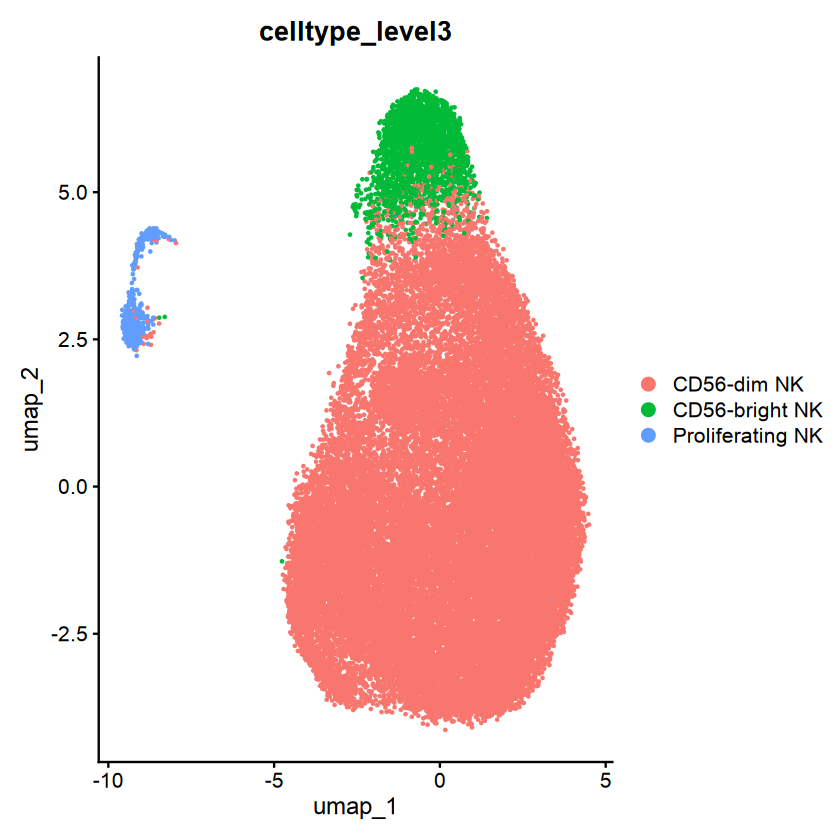

In [37]:
DimPlot(
  ft,
  reduction = "umap",
  group.by = "celltype_level3",
  pt.size = 0.1
)

In [38]:
umap_df <- Embeddings(ft, reduction = "umap")
umap_df <- as.data.frame(umap_df)
umap_df$barcode <- rownames(umap_df)

write.csv(
  umap_df,
  file = glue("data/03_cleandata/ft_{celltype}_UmapCoords.csv"),
  row.names = FALSE
)

In [123]:
Idents(ft) <- "celltype_level3"
markers <- FindAllMarkers(ft, verbose = T)
head(markers)

Calculating cluster CD56-dim NK

Calculating cluster CD56-bright NK

Calculating cluster Proliferating NK



,p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
SELL,0,-2.780145,0.244,0.849,0,CD56-dim NK,SELL
SPON2,0,2.658973,0.848,0.255,0,CD56-dim NK,SPON2
COTL1,0,-4.030023,0.066,0.649,0,CD56-dim NK,COTL1
FGFBP2,0,2.786788,0.841,0.269,0,CD56-dim NK,FGFBP2
GZMK,0,-3.804749,0.058,0.628,0,CD56-dim NK,GZMK
FCGR3A,0,2.365065,0.792,0.274,0,CD56-dim NK,FCGR3A


In [124]:
cell_ordered = c(
    "CD56-dim NK",
    "CD56-bright NK",
    "Proliferating NK"
)

markers$cluster = factor(
    markers$cluster,
    levels = cell_ordered
)

markers %>%
    group_by(cluster) %>%
    filter(p_val_adj < 0.05) %>%
    dplyr::filter(avg_log2FC > 1) %>%
    slice_head(n = 5) %>% # top 5 genes
    ungroup() -> top

top

p_val,avg_log2FC,pct.1,pct.2,p_val_adj,cluster,gene
<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<fct>,<chr>
0,2.658973,0.848,0.255,0,CD56-dim NK,SPON2
0,2.786788,0.841,0.269,0,CD56-dim NK,FGFBP2
0,2.365065,0.792,0.274,0,CD56-dim NK,FCGR3A
0,2.525447,0.641,0.163,0,CD56-dim NK,CCL4
0,1.942534,0.757,0.288,0,CD56-dim NK,GNG2
0,3.022678,0.951,0.246,0,CD56-bright NK,SELL
0,4.088992,0.755,0.058,0,CD56-bright NK,GZMK
0,4.177826,0.729,0.070,0,CD56-bright NK,COTL1
0,3.332162,0.703,0.097,0,CD56-bright NK,TCF7


Warning message:
“Scaling data with a low number of groups may produce misleading results”
Scale for colour is already present.
Adding another scale for colour, which will replace the existing scale.
Scale for size is already present.
Adding another scale for size, which will replace the existing scale.


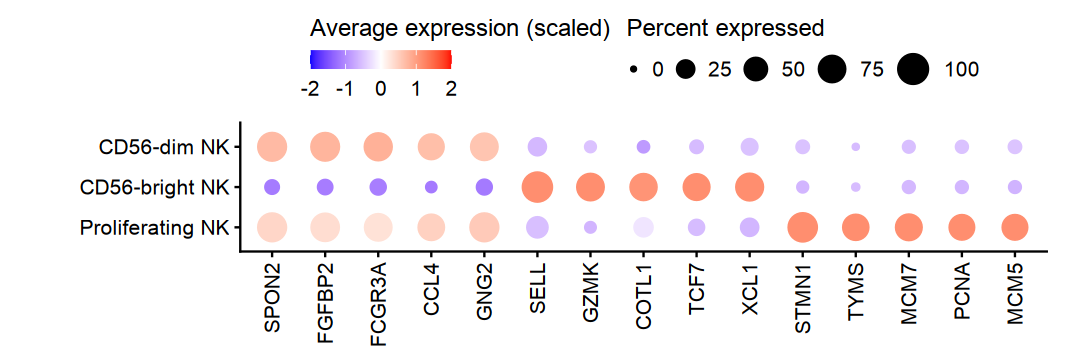

In [127]:
options(repr.plot.width = 9, repr.plot.height = 3)

dot_limits <- c(-2, 2)

p <- DotPlot(
  object   = ft,
  features = unique(unlist(top$gene)),
  group.by = "celltype_level3"
) +
  scale_color_gradient2(
    low = "blue",
    mid = "white",
    high = "red",
    midpoint = 0,
    limits = dot_limits
  ) +
  scale_size(range = c(1, 8), limits = c(0, 100)) +
  scale_y_discrete(limits = rev) +
  theme(
    legend.position = "top",
    legend.direction = "horizontal",
    legend.box = "horizontal",
    legend.justification = "center",
    axis.text.x  = element_text(angle = 90, vjust = 0.5, hjust = 1),
    axis.title.x = element_blank(),
    axis.title.y = element_blank(),
    plot.margin  = margin(t = 10, r = 20, b = 10, l = 50)
  ) +
  guides(
    colour = guide_colourbar(
      title = "Average expression (scaled)",
      direction = "horizontal",
      title.position = "top",
      barwidth  = unit(3, "cm"),
      barheight = unit(0.4, "cm")
    ),
    size = guide_legend(
      title = "Percent expressed",
      direction = "horizontal",
      nrow = 1,
      byrow = TRUE,
      barwidth  = unit(.3, "cm"),
      title.position = "top"
    )
  )

print(p)

In [129]:
ggsave(
  filename = glue("plots/S1/dotplot_{celltype}.svg"),
  plot = p,
  width = 8, height = 3, units = "in", # match your original plot
  device = svglite,                     # ensure vector output
  dpi = 600
)